In [6]:
import numpy as np
import random
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

# Configuración para matplotlib en Colab
%matplotlib inline

In [7]:
# Tamaño del tablero
GRID_SIZE = 9
CELL_SIZE = 50

# Sudoku predefinido (0 representa casillas vacías)
sudoku_puzzle = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

In [404]:
# Posiciones de los números fijos
fixed_positions = {(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE) if sudoku_puzzle[r][c] != 0}

def draw_grid(grid, generation, fitness_score):
    """Dibuja el Sudoku usando Matplotlib"""
    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.title(f"Generación: {generation} - Fitness: {fitness_score}", fontsize=14)
    #plt.imshow(np.ones((GRID_SIZE, GRID_SIZE)) * 0.1, cmap="gray", extent=[0, GRID_SIZE, 0, GRID_SIZE])
    plt.gca().set_facecolor((0.8, 0.8, 0.8))  # RGB: 0.8 es un gris claro

    # Dibujar cuadrícula
    for r in range(GRID_SIZE + 1):
        lw = 2 if r % 3 == 0 else 0.5
        plt.plot([0, GRID_SIZE], [r, r], 'k', linewidth=lw)
        plt.plot([r, r], [0, GRID_SIZE], 'k', linewidth=lw)

    # Añadir números
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if grid[r][c] != 0:
                color = 'darkred' if (r, c) in fixed_positions else 'darkblue'
                plt.text(c + 0.5, GRID_SIZE - r - 0.5, str(grid[r][c]),
                        ha='center', va='center', fontsize=14, color=color, fontweight='bold')

    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.close()  # Cerrar figura para liberar memoria

def generate_population(size):
    """Genera población inicial respetando números fijos"""
    return [np.array([[sudoku_puzzle[r][c] if (r,c) in fixed_positions
                      else random.randint(1, 9) for c in range(9)] for r in range(9)])
            for _ in range(size)]

def fitness_unique(grid):
    #Version Alejandro Sobrino
    '''
    Nunca se pudo alcanzar el resultado con una función de fitness
    basada en encontrar el número de números unicos MAX(fitness) == 243
    '''
    
    #grid = np.array(grid) #necesario para testear con el sudoku original
    """Calcula fitness basado en números únicos por filas y columnas"""
    row_unique = sum(len(set(row)) for row in grid)
    col_unique = sum(len(set(col)) for col in grid.T)

    #Calcula números unicos por cuadricula
    squares_unique = 0
    for square_x in range(3):
        for square_y in range (3):
            #Check for repeats in the square
            square_uniques = []
            for x_i in range(square_x*3,(square_x+1)*3):
                for y_i in range(square_y*3,(square_y+1)*3):
                    if grid[y_i][x_i] not in square_uniques:
                        square_uniques.append(grid[y_i][x_i])
                        squares_unique = squares_unique+1
                        
    return row_unique + col_unique + squares_unique

def fitness_repeated(grid):
    #versión Alejandro Sobrino
    '''
    Esta función de fitness busca los números repetidos en filas, columnas y cuadros.
    El objetivo es MIN(Fitness) == 0
    '''

    #Sacando cuenta de repetidos para columnas y filas
    row_repeated = sum(len(row)-len(set(row)) for row in grid)
    col_repeated = sum(len(col)-len(set(col)) for col in grid.T)
    
    #Calcula números unicos por cuadricula
    squares_repeated = 0
    for square_x in range(3):
        for square_y in range (3):
            #Check for repeats in the square
            square_uniques = []
            for x_i in range(square_x*3,(square_x+1)*3):
                for y_i in range(square_y*3,(square_y+1)*3):
                    if grid[y_i][x_i] not in square_uniques:
                        square_uniques.append(grid[y_i][x_i])
                    else:
                        squares_repeated = squares_repeated + 1
                        

    return row_repeated + col_repeated + squares_repeated

def fitness(grid):
    return fitness_repeated(grid)

def crossover(p1, p2):
    """Cruzamiento por filas con probabilidad 50%"""
    mask = np.random.rand(9) < 0.5
    child = np.where(mask[:, None], p1, p2)
    return child

def mutate(grid, mutation_rate=0.05):
    """Mutación respetando números fijos"""
    mutation_mask = np.random.rand(*grid.shape) < mutation_rate
    random_values = np.random.randint(1, 10, grid.shape)
    return np.where(mutation_mask & ~np.array([[ (r,c) in fixed_positions
                                               for c in range(9)] for r in range(9)]),
                   random_values, grid)

def genetic_algorithm(pop_size=100, max_generations=1000, mutation_rate=0.05, population =[]):
    """Algoritmo genético principal"""
    if len(population) == 0:
        population = generate_population(pop_size)
    best_fitness = 0
    generations_stuck = 0
    past_fitness = 0
    ancestors = []
    generations_since_last_sweep = 0
    gen_stuck_count = []

    for generation in range(max_generations):
        # Evaluar y ordenar población
        population.sort(key=lambda x: fitness(x))
        best_solution = population[0]
        current_fitness = fitness(best_solution)
        generations_since_last_sweep = generations_since_last_sweep + 1
        
        # Mostrar progreso cada 10 generaciones
        if generation % 1000 == 0:
            #draw_grid(best_solution, generation, current_fitness)
            print(f"Generación: {generation:4d} | Fitness: {current_fitness:3d} | Past Fitness: {past_fitness:3d} | Pop Size: {len(population):5d} | Mutation Rate: { mutation_rate:5f} | Gen Stuck: { generations_stuck:3d} | Ancestors: {len(ancestors):3d} |Min posible: 0")
            #time.sleep(0.1)
        #""" Dejar algoritmo original
        if generations_stuck == 0:
            if len(ancestors) < (pop_size):
                ancestors.append(best_solution)
                #print(f"Saving progress ancestor: Current Pop fit avg {sum(fitness(x) for x in population)/len(population):5f} | Ancestors {sum(fitness(x) for x in ancestors)/len(ancestors):5f}, count({len(ancestors):3d})")

         
        if (generations_stuck>200):
            if(generations_stuck%5000 == 0):
                if(fitness(ancestors[-1]) < fitness(best_solution)):
                    ancestors.pop(0)
                    ancestors.append(best_solution)
                #print(f"Repopulating with ancestors: Current Pop fit avg {sum(fitness(x) for x in population)/len(population):5f} count:({len(population)}) | Ancestors {sum(fitness(x) for x in ancestors)/len(ancestors):5f}, count({len(ancestors):3d})")
                population = ancestors.copy()
                while len(population) < pop_size:
                    population = ancestors + population
                population = population[0:pop_size]
                random.shuffle(population)
                #population = ancestors + generate_population(pop_size-len(population))
                #print(f"Repopulating with ancestors ({generation:6d}): Current Pop fit avg {sum(fitness(x) for x in population)/len(population):5f} count:({len(population)}) | Ancestors {sum(fitness(x) for x in ancestors)/len(ancestors):5f}, count({len(ancestors):3d})")
                #generations_stuck = 0    
        #"""
        # Condición de término
        if current_fitness == 0:
            print("\n¡Sudoku resuelto!")
            draw_grid(best_solution, generation, current_fitness)
            return best_solution

        # Selección y reproducción
        parents = population[:pop_size//2]  # Seleccionar mejores 50%
        new_pop = [best_solution.copy()]

        while len(new_pop) < pop_size:
            p1, p2 = random.choices(parents, k=2)
            child = mutate(crossover(p1, p2), mutation_rate)
            new_pop.append(child)

        population = new_pop

        if past_fitness == current_fitness:
            generations_stuck = generations_stuck + 1
        else:
            gen_stuck_count.append(generations_stuck)
            generations_stuck = 0
            past_fitness = current_fitness
            
        ''' hola
        if generations_stuck >= 500:
            population = generate_population(pop_size-1)
            population.append(best_solution)
            print("Refreshing population + best solution")
            #mutation_rate = mutation_rate + 0.002 #No Funcionó aumentar el mutation rate
            #pop_size = pop_size + 100 #Tampoco funcionó aumentar el tamaño de la población
            generations_stuck = 0
        '''
        

    #draw_grid(best_solution, max_generations, best_fitness)
    print(f"Máximo de generaciones alcanzado. Solución no encontrada. Best fitnes: {current_fitness}")
    return best_solution


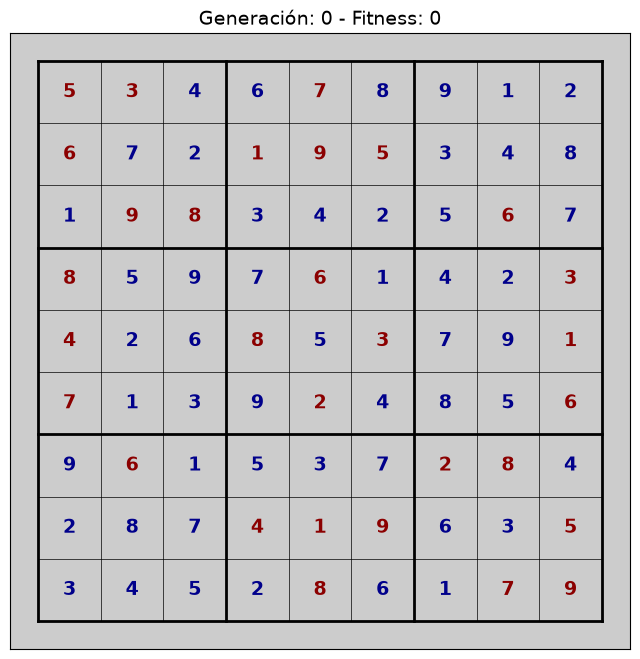

3995.285603400029


In [413]:
# Calcular 100 mejores intentos con la configuración y luego convertirlo en una población
strong_population = []
start_time = time.perf_counter()
end_time = time.perf_counter()
for i in range(150):
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Elapsed Time: {elapsed_time:.6f}|Mejor intento número: {i:3d}")
    strong_population.append(genetic_algorithm(pop_size=200, max_generations=1500, mutation_rate=0.03))

print("OK, tengo las poblaciones")
genetic_algorithm(pop_size=400, max_generations=10000, mutation_rate=0.03,population=strong_population)
end_time = time.perf_counter()
print(end_time-start_time)